<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and response provenance](README.md)

# 01 · Count forecast hours, not compressed rows

How long does a temperature forecast remain below a chosen threshold? Counting rows can give the wrong duration: the NWS grid API merges consecutive equal values into a longer validity interval. We will preserve those intervals, clip them to a 48-hour window, and compare row-weighted and duration-weighted summaries.

**Charlottesville, Virginia: 38.0293° N, 78.4767° W.** Replay uses complete actual point and forecast-grid responses captured on **2026-11-14 UTC**. These are a historical forecast snapshot, not observations or a current warning. Live mode fetches the latest grid for the same location. No simulated temperatures or fallback data are used.

## Set an illustrative temperature threshold

`DATA_MODE` accepts **"replay"** or **"live"**. `TEMPERATURE_THRESHOLD_C` is a finite number from **−40 to 50°C**, inclusive. We classify a known interval as below the threshold only when `value < threshold`; equality belongs to the other known category. Default **5°C** becomes **0°C** in the experiment.

The analysis window is fixed at **48 hours**, starting at the first whole UTC hour at or after the grid's update time. It is half-open: **[start, end)**. Changing the threshold must not move that window or alter the underlying temperatures. Restart Kernel → Run All after editing.

In [1]:
DATA_MODE = "replay"  # "replay" or "live"; same location
TEMPERATURE_THRESHOLD_C = 5.0  # Celsius, strict below; experiment: 0.0

In [2]:
import hashlib
import json
import math
import os
from datetime import UTC, datetime
from pathlib import Path

import haybarn
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.patches import Patch

from replay_source import ReplaySource, request_key

assert DATA_MODE in {"replay", "live"}
assert (
    isinstance(TEMPERATURE_THRESHOLD_C, (int, float))
    and not isinstance(TEMPERATURE_THRESHOLD_C, bool)
    and math.isfinite(TEMPERATURE_THRESHOLD_C)
    and -40 <= TEMPERATURE_THRESHOLD_C <= 50
)
manifest = json.loads(Path("fixtures/manifest.json").read_text())
env_keys = [
    "NWS_API_BASE_URL",
    "NWPS_API_BASE_URL",
    "NWS_GIS_BASE_URL",
    "NWS_RASTER_BASE_URL",
    "NWS_TROPICAL_BASE_URL",
    "NWS_EVENT_BASE_URL",
    "NWS_AVIATION_BASE_URL",
    "NWS_NDBC_BASE_URL",
    "NWS_SWPC_BASE_URL",
    "NWS_MRMS_BASE_URL",
    "NWS_USER_AGENT",
]
previous_env = {key: os.environ.pop(key, None) for key in env_keys}
replay = ReplaySource(Path("fixtures")) if DATA_MODE == "replay" else None
if replay:
    os.environ["NWS_API_BASE_URL"] = replay.url
os.environ["NWS_USER_AGENT"] = "vgi-nws-notebooks/1.0 (https://query.farm)"
started = datetime.now(UTC)
colors = {
    "Below threshold": "#287d85",
    "At or above": "#bd7735",
    "Missing value": "#888888",
    "No interval": "#cccccc",
}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {"figure.dpi": 125, "text.parse_math": False, "axes.spines.top": False, "axes.spines.right": False}
)


def prose(text):
    display(Markdown(text))


def number(value):
    return "unavailable" if pd.isna(value) else f"{value:.3f}"


def finish(fig):
    fig.text(
        0.01,
        0.01,
        f"NWS grid · Charlottesville · {DATA_MODE} · response capture {source_time} · forecast, not observation",
        fontsize=8,
        color="#555555",
    )
    fig.tight_layout(rect=(0, 0.08, 1, 0.90))
    plt.show()


con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-nws/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/worktrees/vgi-nws/notebooks/pyproject.toml.

## Materialize the native intervals once

The visible Bun command uses the notebook companion to fetch an immutable remote revision, install its frozen dependencies in a versioned cache and launch the real TypeScript worker. It needs no local worker checkout. See the README for cache behavior.

`grid_series` resolves the point and downloads its complete grid document, even though we select only `temperature`. The variable option and a SQL LIMIT do not shrink those HTTP responses. All subsequent selection is local. The worker preserves the native Celsius unit, update timestamp and exclusive validity ends; it does not invent hourly samples.

[NWS's gridpoint FAQ](https://weather-gov.github.io/api/gridpoints) explains the merged intervals and missing values. Temperature is suitable for duration weighting here; accumulation amounts and daily extrema would require different interpretations.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nws' (
 TYPE vgi,
 LOCATION 'bun run github_worker.ts Query-farm/vgi-nws c672f94632fca2541b805ead4d7f861317fe34e8 src/worker.ts'
);
CREATE TABLE temperatures AS
SELECT * FROM nws.main.grid_series(38.0293,-78.4767,variable:='temperature');
CREATE TABLE analysis_window AS
WITH anchor AS (
 SELECT to_timestamp(ceil(epoch(max(updated_at))/3600)*3600) AS window_start FROM temperatures
)
SELECT window_start,window_start+INTERVAL '48 hours' AS window_end FROM anchor;

,Count


In [4]:
%%sql availability <<
SELECT count(*) AS native_intervals,
 count(*) FILTER(WHERE value IS NULL) AS missing_temperature_intervals,
 min(valid_from) AS first_valid_utc,max(valid_to) AS last_valid_utc,
 min(updated_at) AS grid_updated_utc,min(unit) AS native_unit,
 min(date_diff('second',valid_from,valid_to)/3600.0) AS shortest_hours,
 max(date_diff('second',valid_from,valid_to)/3600.0) AS longest_hours
FROM temperatures;

In [5]:
retrieved = datetime.now(UTC)
source_time = (manifest["capture_finished_utc"] if replay else retrieved.isoformat())[:19] + " UTC"
assert con.execute(
    "SELECT count(*)>0 AND count(DISTINCT updated_at)=1 AND count(DISTINCT unit)=1 AND min(unit)='wmoUnit:degC' FROM temperatures"
).fetchone()[0]
assert (
    con.execute(
        "SELECT count(*) FROM temperatures WHERE valid_from IS NULL OR valid_to IS NULL OR valid_to<=valid_from OR updated_at IS NULL OR variable<>'temperature'"
    ).fetchone()[0]
    == 0
)
assert (
    con.execute(
        "SELECT count(*) FROM (SELECT *,lag(valid_to) OVER(ORDER BY valid_from) AS previous_end FROM temperatures) WHERE valid_from<previous_end"
    ).fetchone()[0]
    == 0
)
fingerprint = hashlib.sha256(
    json.dumps(
        con.execute(
            "SELECT variable,valid_from,valid_to,value,unit,updated_at FROM temperatures ORDER BY valid_from"
        ).fetchall(),
        default=str,
        separators=(",", ":"),
    ).encode()
).hexdigest()
if replay:
    assert sorted(map(request_key, replay.requests)) == sorted(
        request_key(e["request_path"]) for e in manifest["entries"]
    )
    raw = json.loads(Path("fixtures/grid.json").read_text())["properties"]["temperature"]["values"]
    expected = []
    for row in raw:
        start_text, end_text = row["validTime"].split("/")
        start_time = datetime.fromisoformat(start_text)
        end_time = (
            start_time + pd.Timedelta(end_text)
            if end_text.startswith("P")
            else datetime.fromisoformat(end_text)
        )
        expected.append((start_time, end_time, row["value"]))
    assert (
        sorted(expected)
        == con.execute("SELECT valid_from,valid_to,value FROM temperatures ORDER BY valid_from").fetchall()
    )
    request_note = f"Replay served **{len(replay.requests)} exact requests**: the point and full grid document. All **{len(raw)} temperature intervals** agree with the recorded values and an independent ISO-duration decoding."
else:
    request_note = f"Live retrieval ran from **{started.isoformat()}** to **{retrieved.isoformat()}**. HTTP attempts are not instrumented; retries may occur."
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/request-audit.json").write_text(
    json.dumps(
        {
            "mode": DATA_MODE,
            "requests": replay.requests if replay else None,
            "fingerprint": fingerprint,
            "started_utc": started.isoformat(),
            "finished_utc": retrieved.isoformat(),
        },
        indent=2,
    )
)
display(availability)
window = con.execute("SELECT * FROM analysis_window").df()
display(window)
prose(
    f"{request_note} Source capture: **{source_time}**. The grid update and forecast validity times above are different clocks. Intervals span **{availability.shortest_hours.iloc[0]:g}–{availability.longest_hours.iloc[0]:g} hours**, so equal row weights need not represent equal time. Temperature fingerprint: `{fingerprint}`."
)

/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/ipykernel_89329/973740630.py:37: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start_time + pd.Timedelta(end_text)


,native_intervals,missing_temperature_intervals,first_valid_utc,last_valid_utc,grid_updated_utc,native_unit,shortest_hours,longest_hours
0,179,0,2026-11-13 19:00:00-05:00,2026-11-21 20:00:00-05:00,2026-11-14 01:22:53-05:00,wmoUnit:degC,1.0,3.0


,window_start,window_end
0,2026-11-14 02:00:00-05:00,2026-11-16 02:00:00-05:00


Replay served **2 exact requests**: the point and full grid document. All **179 temperature intervals** agree with the recorded values and an independent ISO-duration decoding. Source capture: **2026-11-14T08:52:40 UTC**. The grid update and forecast validity times above are different clocks. Intervals span **1–3 hours**, so equal row weights need not represent equal time. Temperature fingerprint: `f88c30ff8f20f78c6bb92ce9a8f4ff8d7f633fb248c605f9b5c44aa631c0fca5`.

## Clip before classifying

Intersect every native interval with the half-open analysis window. An interval ending exactly at the window start or beginning exactly at the window end contributes nothing. Partial boundary intervals contribute only their overlap duration. This is interval arithmetic, not interpolation.

The plot draws each known value as a separate horizontal segment. It does not join gaps or connect temperatures with sloping lines. The lower panel shows each clipped interval's duration. Missing values and uncovered time are counted separately in the next summary.

In [6]:
%%sql
CREATE TABLE clipped AS
SELECT t.*,greatest(t.valid_from,w.window_start) AS clipped_start,
 least(t.valid_to,w.window_end) AS clipped_end,
 date_diff('second',greatest(t.valid_from,w.window_start),least(t.valid_to,w.window_end))/3600.0 AS hours,
 CASE WHEN value IS NULL THEN 'Missing value'
 WHEN value<{{TEMPERATURE_THRESHOLD_C}} THEN 'Below threshold' ELSE 'At or above' END AS category
FROM temperatures t CROSS JOIN analysis_window w
WHERE t.valid_from<w.window_end AND t.valid_to>w.window_start;

,Count


In [7]:
%%sql interval_table <<
SELECT clipped_start,clipped_end,hours,value AS temperature_c,category
FROM clipped ORDER BY clipped_start LIMIT 12;

,clipped_start,clipped_end,hours,temperature_c,category
0,2026-11-14 02:00:00-05:00,2026-11-14 04:00:00-05:00,2.0,1.111111,Below threshold
1,2026-11-14 04:00:00-05:00,2026-11-14 05:00:00-05:00,1.0,0.000000,Below threshold
2,2026-11-14 05:00:00-05:00,2026-11-14 07:00:00-05:00,2.0,-0.555556,Below threshold
3,2026-11-14 07:00:00-05:00,2026-11-14 08:00:00-05:00,1.0,-1.111111,Below threshold
4,2026-11-14 08:00:00-05:00,2026-11-14 09:00:00-05:00,1.0,0.555556,Below threshold
5,2026-11-14 09:00:00-05:00,2026-11-14 10:00:00-05:00,1.0,5.555556,At or above
6,2026-11-14 10:00:00-05:00,2026-11-14 11:00:00-05:00,1.0,8.333333,At or above
7,2026-11-14 11:00:00-05:00,2026-11-14 12:00:00-05:00,1.0,10.000000,At or above
8,2026-11-14 12:00:00-05:00,2026-11-14 13:00:00-05:00,1.0,11.111111,At or above
9,2026-11-14 13:00:00-05:00,2026-11-14 15:00:00-05:00,2.0,11.666667,At or above


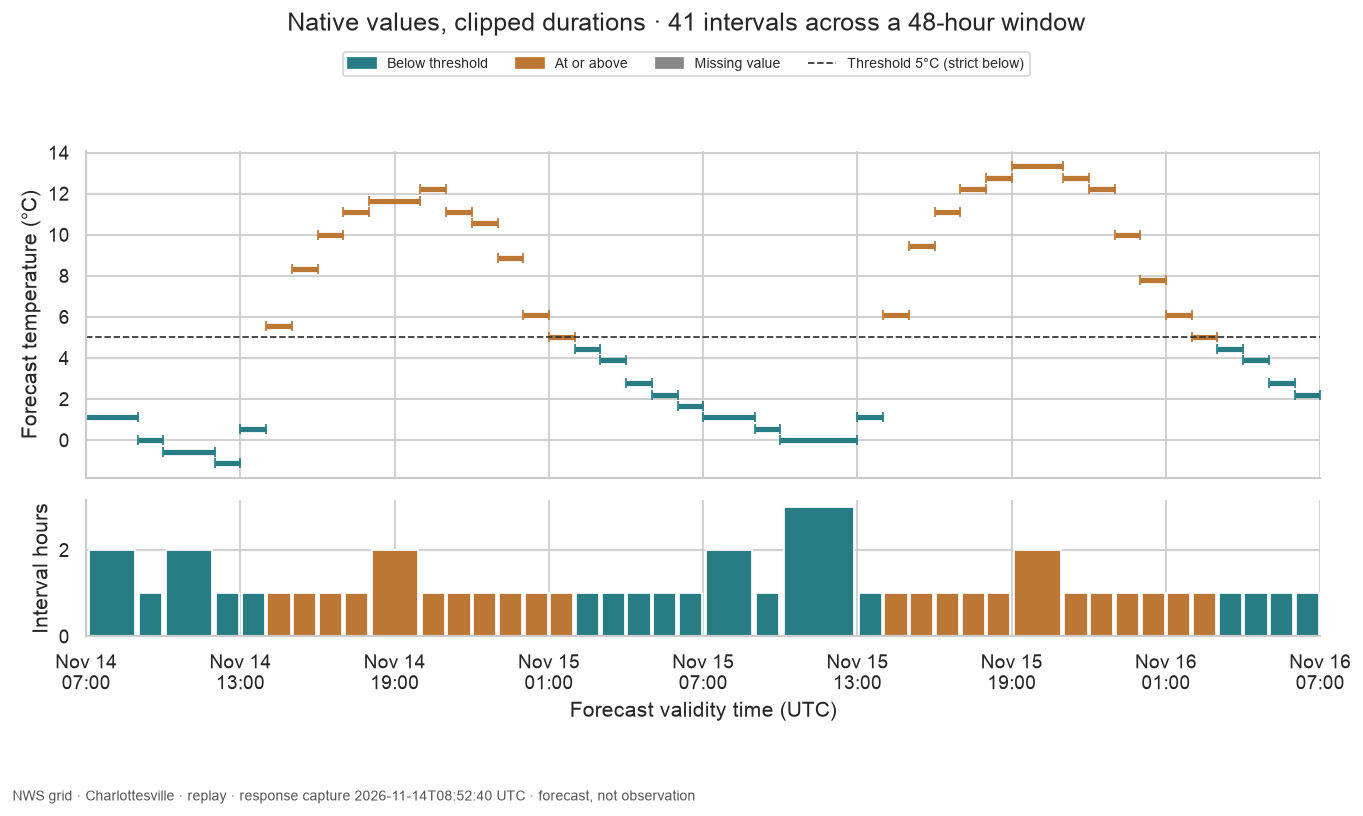

In [8]:
display(interval_table)
rows = con.execute("SELECT * FROM clipped ORDER BY clipped_start").df()
assert len(rows) > 0 and (rows.hours > 0).all()
assert (
    con.execute(
        "SELECT count(*) FROM clipped,analysis_window WHERE clipped_start<window_start OR clipped_end>window_end"
    ).fetchone()[0]
    == 0
)
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [2.4, 1]})
for r in rows.itertuples():
    x0 = mdates.date2num(r.clipped_start)
    x1 = mdates.date2num(r.clipped_end)
    if pd.notna(r.value):
        axes[0].hlines(r.value, x0, x1, color=colors[r.category], linewidth=3)
        axes[0].plot(
            [x0, x1], [r.value, r.value], linestyle="none", marker="|", color=colors[r.category], markersize=6
        )
    else:
        axes[0].axvspan(x0, x1, color=colors[r.category], alpha=0.3)
    axes[1].bar((x0 + x1) / 2, r.hours, width=(x1 - x0) * 0.9, color=colors[r.category])
axes[0].axhline(
    TEMPERATURE_THRESHOLD_C,
    color="#333333",
    linestyle="--",
    linewidth=1,
    label=f"Threshold {TEMPERATURE_THRESHOLD_C:g}°C (strict below)",
)
axes[0].set(ylabel="Forecast temperature (°C)")
fig.legend(
    handles=[
        Patch(color=colors["Below threshold"], label="Below threshold"),
        Patch(color=colors["At or above"], label="At or above"),
        Patch(color=colors["Missing value"], label="Missing value"),
        axes[0].lines[-1],
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    fontsize=8,
    ncols=4,
)
axes[1].set(ylabel="Interval hours", xlabel="Forecast validity time (UTC)")
axes[1].xaxis.set_major_locator(mdates.HourLocator(interval=6, tz=UTC))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%H:%M", tz=UTC))
axes[1].set_xlim(mdates.date2num(window.window_start.iloc[0]), mdates.date2num(window.window_end.iloc[0]))
fig.suptitle(f"Native values, clipped durations · {len(rows)} intervals across a 48-hour window")
finish(fig)

## Weight by elapsed hours, and keep the denominators visible

The time-weighted mean is `sum(value × hours) / sum(known hours)`. The ordinary interval mean assigns one equal vote to every compressed row. Both summarize the returned forecast, but only the first weights by elapsed time.

The category chart compares row counts with hours in separate panels. They have different units and scales. Uncovered time has an hour total but no interval count. Missing-temperature intervals retain their duration; neither missing nor uncovered hours count as below-threshold evidence.

In [9]:
%%sql
CREATE TABLE categories AS
SELECT labels.category,count(c.category) AS interval_rows,coalesce(sum(c.hours),0) AS hours
FROM (VALUES ('Below threshold'),('At or above'),('Missing value')) labels(category)
LEFT JOIN clipped c USING(category) GROUP BY labels.category
UNION ALL SELECT 'No interval',NULL,48-coalesce(sum(hours),0) FROM clipped;

,Count


In [10]:
%%sql summary <<
SELECT count(*) AS selected_intervals,sum(hours) AS covered_hours,
 sum(hours) FILTER(WHERE value IS NOT NULL) AS known_hours,
 sum(value*hours)/nullif(sum(hours) FILTER(WHERE value IS NOT NULL),0) AS time_weighted_mean_c,
 avg(value) AS equal_interval_mean_c,
 coalesce(sum(hours) FILTER(WHERE category='Below threshold'),0) AS below_hours,
 count(*) FILTER(WHERE category='Below threshold') AS below_intervals
FROM clipped;

,selected_intervals,covered_hours,known_hours,time_weighted_mean_c,equal_interval_mean_c,below_hours,below_intervals
0,41,48.0,48.0,5.775463,6.111111,23.0,18


,category,interval_rows,hours
0,Below threshold,18,23.0
1,At or above,23,25.0
2,Missing value,0,0.0
3,No interval,<NA>,0.0


Below **5°C**, **18 intervals** represent **23 forecast hours**. There are **48 known-temperature hours** within **48 covered hours** of the 48-hour window. The duration-weighted mean is **5.775°C**, compared with **6.111°C** for equal interval weights. These describe this forecast snapshot; they do not verify what actually occurred.

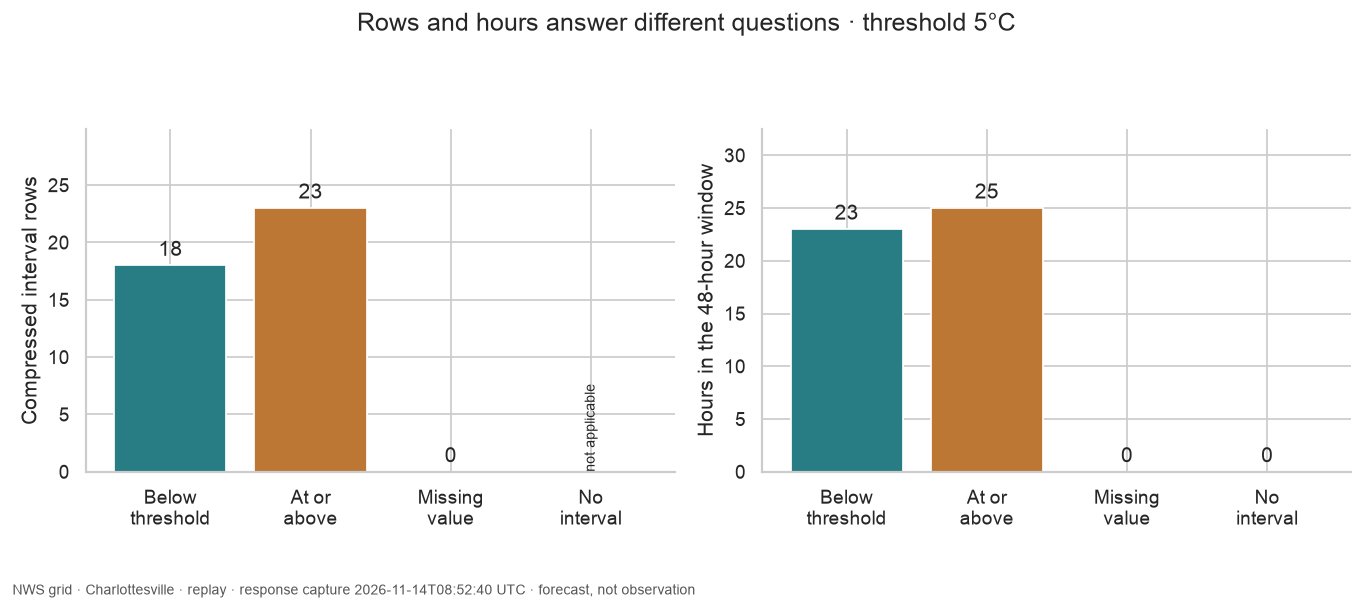

In [11]:
display(summary)
categories = con.execute(
    "SELECT * FROM categories ORDER BY CASE category WHEN 'Below threshold' THEN 0 WHEN 'At or above' THEN 1 WHEN 'Missing value' THEN 2 ELSE 3 END"
).df()
display(categories)
assert abs(categories.hours.sum() - 48) < 1e-10 and categories.hours.min() >= 0
assert categories.interval_rows.sum() == len(rows)
assert (
    con.execute(
        "SELECT count(*) FROM clipped WHERE category IS DISTINCT FROM CASE WHEN value IS NULL THEN 'Missing value' WHEN value<? THEN 'Below threshold' ELSE 'At or above' END",
        [TEMPERATURE_THRESHOLD_C],
    ).fetchone()[0]
    == 0
)
r = summary.iloc[0]
assert r.below_hours <= r.covered_hours <= 48 and r.below_intervals <= r.selected_intervals
prose(
    f"Below **{TEMPERATURE_THRESHOLD_C:g}°C**, **{int(r.below_intervals)} intervals** represent **{r.below_hours:g} forecast hours**. There are **{r.known_hours:g} known-temperature hours** within **{r.covered_hours:g} covered hours** of the 48-hour window. The duration-weighted mean is **{number(r.time_weighted_mean_c)}°C**, compared with **{number(r.equal_interval_mean_c)}°C** for equal interval weights. These describe this forecast snapshot; they do not verify what actually occurred."
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, column, label in zip(
    axes, ["interval_rows", "hours"], ["Compressed interval rows", "Hours in the 48-hour window"], strict=True
):
    for i, row in enumerate(categories.itertuples()):
        value = getattr(row, column)
        if pd.isna(value):
            ax.text(i, 0, "not applicable", rotation=90, ha="center", va="bottom", fontsize=8)
        else:
            bar = ax.bar(i, value, color=colors[row.category])
            ax.bar_label(bar, fmt="%g", padding=3)
    ax.set(
        xticks=range(len(categories)),
        xticklabels=["Below\nthreshold", "At or\nabove", "Missing\nvalue", "No\ninterval"],
        ylabel=label,
    )
    ax.set_ylim(0, max(1, categories[column].max()) * 1.3)
    ax.set_xlim(-0.6, 3.6)
fig.suptitle(f"Rows and hours answer different questions · threshold {TEMPERATURE_THRESHOLD_C:g}°C")
finish(fig)

## Experiment: lower the threshold to 0°C

Keep `DATA_MODE="replay"` and change only `TEMPERATURE_THRESHOLD_C` from **5.0 to 0.0**. Predict that below-threshold hours cannot increase. Compare the count of qualifying intervals with their total hours; these quantities need not change in the same proportion.

The fingerprint, 48-hour UTC window, coverage and both temperature means must remain unchanged. Only classification and threshold annotations change. Restore **5.0** afterwards. This illustrative threshold analysis is not a frost warning or a prediction of damage: grid air temperature, local conditions and actual outcomes are different quantities.

In [12]:
con.close()
if replay:
    replay.close()
for key, value in previous_env.items():
    if value is None:
        os.environ.pop(key, None)
    else:
        os.environ[key] = value

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)